# eda_prepare — Perovskite dataset: EDA

สมุดนี้ทำ **EDA อย่างเดียว** — PART 1/2/3 (text-clean, value-format, property-decompose) ย้ายไปอยู่ที่ `column_prepare.ipynb` ทั้งหมดแล้ว (2026-07-15) ซึ่งเขียนออก `processed/prepared/` ที่สมุดนี้อ่านต่อ

> ⚠️ ต้องรัน `column_prepare.ipynb` (Run All) ให้เสร็จก่อนเสมอ ก่อนรันสมุดนี้

## Setup

In [1]:
import re
from collections import Counter
from pathlib import Path
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "processed" / "normalize").exists() else Path.cwd().parent
print("repo root:", ROOT)

repo root: D:\University\Year 4 Semester 1 (Intern)\Perovskites-Research


---
# PART 4 · EDA — Perovskite Solar Cell (process-focused)

*(เดิมคือ `EDA.ipynb` — โครงเดิมครบ แต่เปลี่ยนแหล่งข้อมูล)* ต่างจากเวอร์ชันเก่า 2 จุด:

1. อ่านจาก **`processed/prepared/`** (ผ่าน PART 1–3 แล้ว) แทน `processed/normalize/`
2. **สร้าง device-level view (`ml`) ใน memory** แทนการอ่าน `ml_dataset.csv`
   — ไฟล์นั้นยังเป็นเวอร์ชันก่อน clean (FF ปนสเกล, bandgap ปนชั้น) จะ regenerate หลังปิด PART 5

โฟกัส: ภาพรวม + missing → การกระจาย target (PCE) → สถานะ data-quality flags →
features เชิงกระบวนการ → correlation → ความเสถียร

> สี: palette ผ่าน validator (PASS; CVD ΔE 24.2) — 3 สีมี contrast บนพื้นต่ำกว่า 3:1
> จึงใส่ direct labels กำกับตัวเลขบนกราฟแท่งเสมอ (ตามข้อบังคับของ palette นี้)


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# --- validated categorical palette (fixed order, colorblind-safe) ---
CAT = ["#2a78d6", "#1baf7a", "#eda100", "#008300",
       "#4a3aa7", "#e34948", "#e87ba4", "#eb6834"]
BLUE = "#2a78d6"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
DIVERGING = LinearSegmentedColormap.from_list("bwr_cvd", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "axes.unicode_minus": False,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "figure.dpi": 110,
})

def style(ax, title=None, xlabel=None, ylabel=None):
    if title: ax.set_title(title, loc="left", pad=10)
    if xlabel is not None: ax.set_xlabel(xlabel)
    if ylabel is not None: ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)
    return ax

tp = {p.stem: pd.read_csv(p) for p in sorted((ROOT / "processed" / "prepared").glob("*.csv"))}
{name: df.shape for name, df in tp.items()}

{'devices': (44, 4),
 'layers': (352, 10),
 'materials': (543, 8),
 'process': (702, 9),
 'properties': (563, 13),
 'stability': (62, 19),
 'vendors': (644, 8)}

## 4.1) สร้าง device-level view (`ml`) จากตารางที่ prepared แล้ว

logic เดียวกับ `build_ml_table()` ใน `scripts/reschema.py` แต่ดีกว่า 3 จุด:
- JV metrics ดึงจาก `base_property` (ผลของ PART 3) แทน keyword matching หยาบ ๆ — champion = max ของ `value_parsed`
- `ff_max` สเกลเดียวกันทั้งชุด (%) เพราะแปลงแล้วใน PART 3
- `bandgap_psk` กรองเฉพาะ `layer == "PSK"` — แก้ปัญหาเดิมที่ band gap ของ HTL (3.85 eV) ปนเข้ามา


In [3]:
lay, pr, prop = tp["layers"], tp["process"], tp["properties"]

ml = tp["devices"][["device_id", "doi_raw", "sample_no"]].copy()

# โครงสร้าง stack
stack = (lay.dropna(subset=["material"]).groupby("device_id")
            .agg(n_layers=("layer_id", "nunique")))
for ltype, col in {"HTL": "htl_material", "ETL": "etl_material", "PSK": "perovskite",
                   "Anode": "anode", "Cathode": "cathode"}.items():
    m = (lay[lay["layer_type"] == ltype].dropna(subset=["material"])
         .groupby("device_id")["material"].first().rename(col))
    stack = stack.join(m)
ml = ml.merge(stack, on="device_id", how="left")

# process features (ชื่อ canonical แล้วจาก PART 1 — match ตรง ๆ ได้เลย)
proc = pr.groupby("device_id").agg(n_process_steps=("step_order", "count"))
proc["n_spin_coating"] = pr[pr["process_type"] == "Spin coating"].groupby("device_id").size()
proc["has_antisolvent"] = pr[pr["process_type"] == "Antisolvent"].groupby("device_id").size().gt(0)
ml = ml.merge(proc, on="device_id", how="left")
ml["n_spin_coating"] = ml["n_spin_coating"].fillna(0).astype(int)
ml["has_antisolvent"] = ml["has_antisolvent"].fillna(False)

# JV metrics: champion = max ของ value_parsed ต่อ base
jv = (prop.dropna(subset=["value_parsed"])
          .query("base_property in ['PCE', 'Voc', 'Jsc', 'FF']")
          .pivot_table(index="device_id", columns="base_property",
                       values="value_parsed", aggfunc="max")
          .rename(columns={"PCE": "pce_max", "Voc": "voc_max",
                           "Jsc": "jsc_max", "FF": "ff_max"}))
ml = ml.merge(jv, on="device_id", how="left")

# band gap เฉพาะชั้น perovskite
bg = (prop[(prop["base_property"].str.lower() == "optical band gap") & (prop["layer"] == "PSK")]
      .groupby("device_id")["value_parsed"].max().rename("bandgap_psk"))
ml = ml.merge(bg, on="device_id", how="left")

print(f"{ml.shape[0]} devices | {ml['doi_raw'].nunique()} publications")
ml.head()

44 devices | 15 publications


,device_id,doi_raw,sample_no,n_layers,htl_material,etl_material,perovskite,anode,cathode,n_process_steps,n_spin_coating,has_antisolvent,ff_max,jsc_max,pce_max,voc_max,bandgap_psk
0,10.1002admi.202500231_Sample1,10.1002admi.202500231,1,6,NiOx NPs,C60,[ (Cs.05FA.79MA.16)Pb(I.87Br.13)3 ],ITO,Ag,18,3,False,76.0,20.97,16.31,1.020,1.609
1,10.1002admi.202500231_Sample2,10.1002admi.202500231,2,7,NiOx NPs,C60,[ (Cs.05FA.79MA.16)Pb(I.87Br.13)3 ],ITO,Ag,19,3,False,75.0,22.01,17.11,1.040,1.620
2,10.1002admi.202500231_Sample3,10.1002admi.202500231,3,7,NiOx NPs,C60,[ (Cs.05FA.79MA.16)Pb(I.87Br.13)3 ],ITO,Ag,19,3,False,78.0,21.86,16.97,1.000,1.620
3,10.1002admi.202500231_Sample4,10.1002admi.202500231,4,7,NiOx NPs,C60,[ (Cs.05FA.79MA.16)Pb(I.87Br.13)3 ],ITO,Ag,19,3,False,79.0,20.79,16.25,0.990,1.620
4,10.1016j.jechem.2021.11.029_Sample1,10.1016j.jechem.2021.11.029,1,7,NiOx,PCBM,(FA0.85MA0.15)0.95Cs0.05Pb(I0.85Br0.15)3,ITO,Ag,13,6,False,79.6,21.32,17.83,1.065,NaN


In [4]:
ml.describe(include="number").T.round(2)

,count,mean,std,min,25%,50%,75%,max
sample_no,44.0,2.16,1.14,1.00,1.00,2.00,3.00,5.00
n_layers,44.0,7.11,0.75,6.00,7.00,7.00,8.00,8.00
n_process_steps,44.0,15.34,2.27,11.00,14.00,15.00,16.25,20.00
n_spin_coating,44.0,4.84,1.31,3.00,4.00,5.00,6.00,7.00
ff_max,43.0,77.72,4.70,65.39,75.10,78.46,81.19,84.68
jsc_max,43.0,23.15,2.14,18.26,21.36,23.49,24.72,26.55
pce_max,43.0,20.01,3.45,13.98,17.20,20.16,22.78,26.50
voc_max,43.0,1.10,0.07,0.97,1.04,1.11,1.15,1.24
bandgap_psk,4.0,1.62,0.01,1.61,1.62,1.62,1.62,1.62


## 4.2) Missing data

ก่อนเทรนต้องรู้ว่าคอลัมน์ไหนมีค่าไม่ครบ — `bandgap_psk` มีน้อยเพราะมีไม่กี่ paper ที่รายงาน
optical band gap ของชั้น perovskite ตรง ๆ (แต่ตอนนี้**ความหมายถูกต้อง**แล้ว ไม่ปนของ HTL)


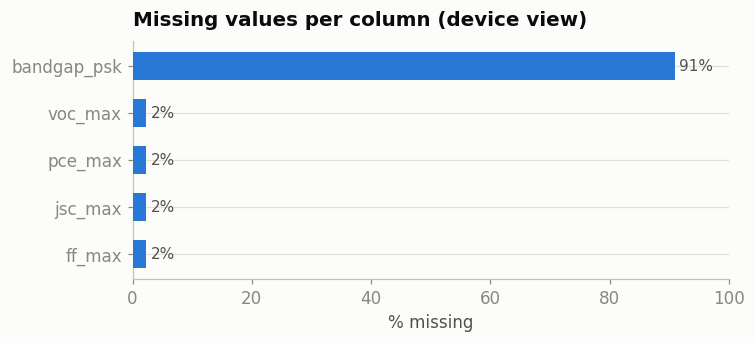

In [5]:
miss = ml.isna().mean().mul(100).sort_values()
miss = miss[miss > 0]
if len(miss):
    fig, ax = plt.subplots(figsize=(7, max(2, 0.45 * len(miss) + 1)))
    ax.barh(miss.index, miss.values, color=BLUE, height=0.6, zorder=3)
    for y, v in enumerate(miss.values):
        ax.text(v + 0.8, y, f"{v:.0f}%", va="center", color=INK2, fontsize=10)
    ax.set_xlim(0, 100)
    style(ax, "Missing values per column (device view)", "% missing", None)
    plt.tight_layout(); plt.show()
else:
    print("no missing values")

## 4.3) การกระจายของ PCE (target) และ JV metrics

PCE คือ target หลักของการทำนายประสิทธิภาพจากกระบวนการ — และตอนนี้ FF เป็น % ทั้งชุดแล้ว
(แผง FF จะไม่มีก้อนแปลก ๆ ที่ 0.7 อีก)


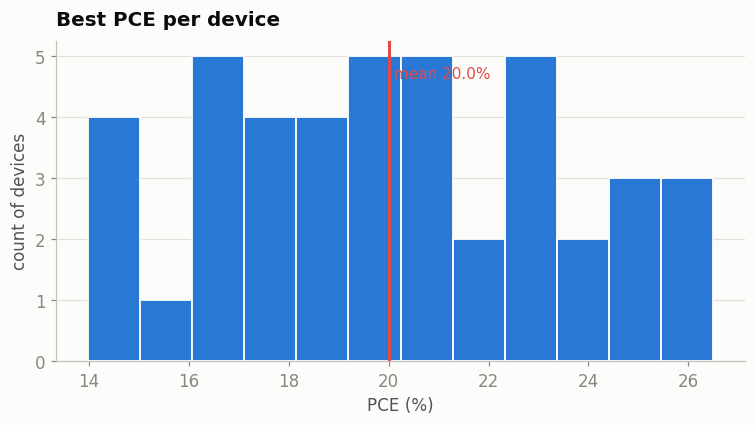

In [6]:
pce = ml["pce_max"].dropna()
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(pce, bins=12, color=BLUE, edgecolor="#fcfcfb", linewidth=1.2, zorder=3)
ax.axvline(pce.mean(), color="#e34948", lw=2, zorder=4)
ax.text(pce.mean(), ax.get_ylim()[1] * 0.92, f" mean {pce.mean():.1f}%",
        color="#e34948", fontsize=10, va="top")
style(ax, "Best PCE per device", "PCE (%)", "count of devices")
plt.tight_layout(); plt.show()

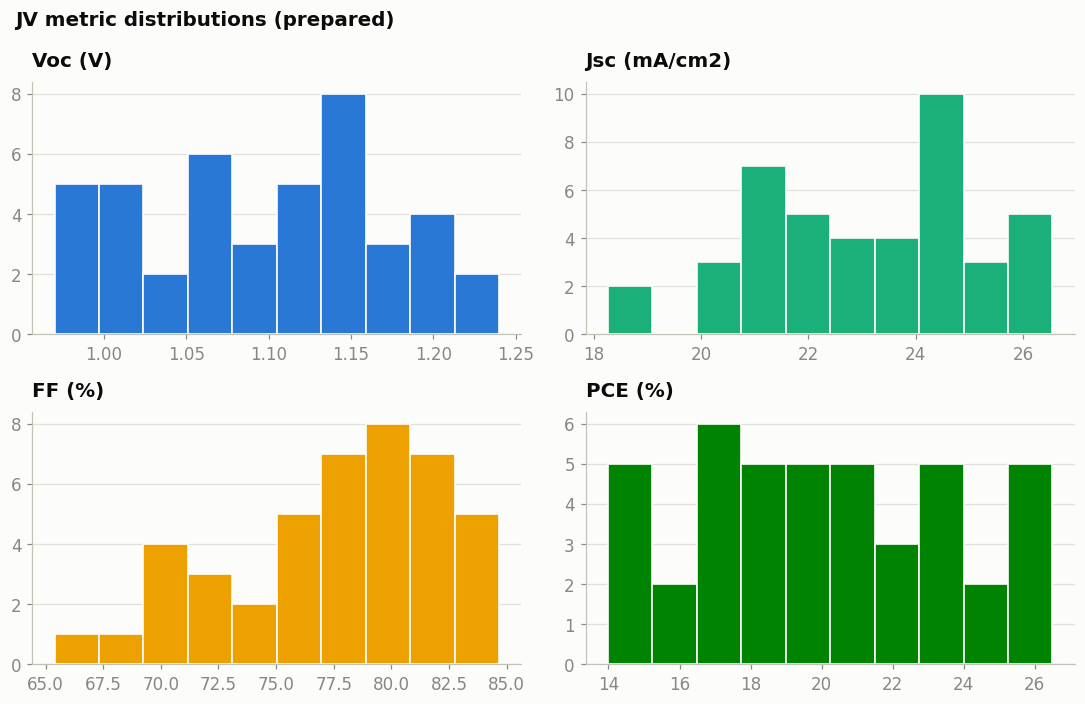

In [7]:
metrics = [("voc_max", "Voc (V)"), ("jsc_max", "Jsc (mA/cm2)"),
           ("ff_max", "FF (%)"), ("pce_max", "PCE (%)")]
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
for (col, label), ax, c in zip(metrics, axes.ravel(), CAT):
    d = ml[col].dropna()
    ax.hist(d, bins=10, color=c, edgecolor="#fcfcfb", linewidth=1.1, zorder=3)
    style(ax, label, None, None)
    ax.grid(axis="x", visible=False)
fig.suptitle("JV metric distributions (prepared)", x=0.02, ha="left",
             fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()

## 4.4) สถานะ Data-quality flags — เทียบกับที่ EDA เวอร์ชันเก่าเคยเจอ

| flag ที่ EDA เดิมเจอ | สถานะตอนนี้ |
|---|---|
| 1. `ff_max` ปนหน่วย (0.7x กับ 7x–8x) | ✅ **แก้แล้ว** (PART 3, ×100 + audit) — กราฟล่างยืนยัน |
| 2. `bandgap_max` ปนความหมาย (HTL 3.85 eV ปนกับ perovskite) | ✅ **แก้แล้ว** — `bandgap_psk` กรอง `layer == "PSK"` (เหลือ `Bandgap`/`Energy gap` 2 แถวรอกลุ่ม #8 ใน PART 5.1) |
| 3. ชื่อวัสดุ HTL หลายแบบ (`NiOx`/`NiOx NPs`/`NiOx Nanoparticles`) | ⏳ **ยังรอ** — เป็น semantic (ต้องรู้ว่าคือของเดียวกันจริง) กราฟล่างแสดงสภาพปัจจุบัน |
| 4. `process.parameter` เป็น string ปนหน่วย (`"80,12"` + `"C, hr"`) | ⏳ **ยังรอ** — ต้องออกแบบ schema แตก step-parameter |


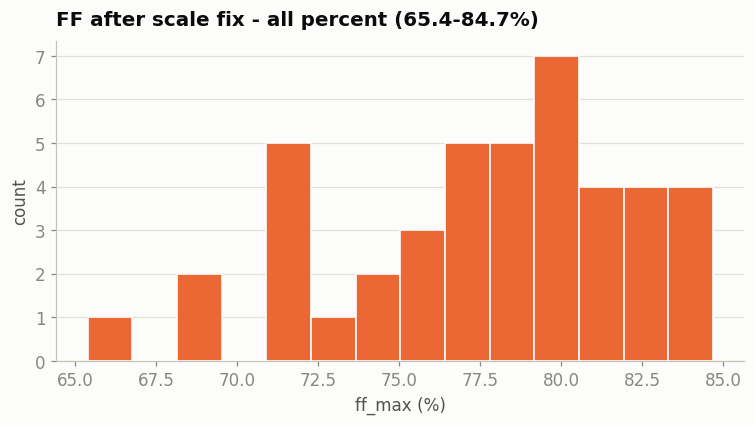

ไม่มีค่า FF <= 1 เหลืออยู่: True


In [8]:
ff = ml["ff_max"].dropna()
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(ff, bins=14, color="#eb6834", edgecolor="#fcfcfb", linewidth=1.1, zorder=3)
style(ax, f"FF after scale fix - all percent ({ff.min():.1f}-{ff.max():.1f}%)",
      "ff_max (%)", "count")
plt.tight_layout(); plt.show()
print("ไม่มีค่า FF <= 1 เหลืออยู่:", bool((ff > 1).all()))

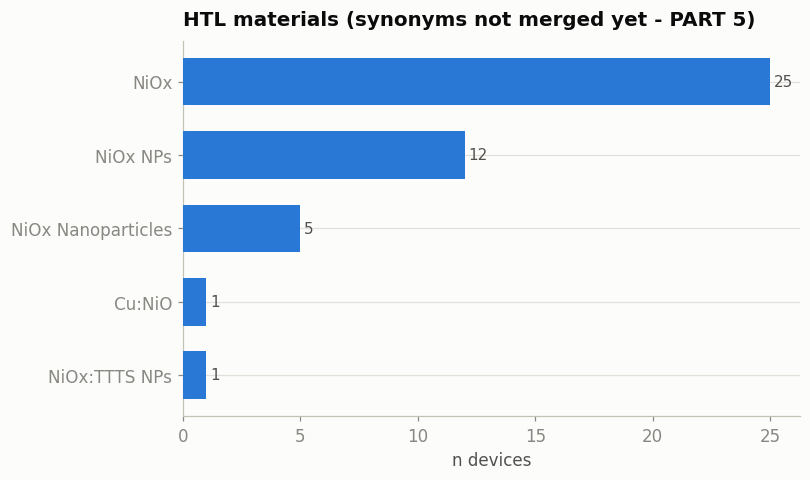

In [9]:
htl = tp["layers"].query("layer_type == 'HTL'")["material"].dropna()
vc = htl.value_counts().head(12)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(vc.index[::-1], vc.values[::-1], color=BLUE, height=0.65, zorder=3)
for y, v in enumerate(vc.values[::-1]):
    ax.text(v + 0.15, y, str(v), va="center", color=INK2, fontsize=10)
style(ax, "HTL materials (synonyms not merged yet - PART 5)", "n devices", None)
plt.tight_layout(); plt.show()

## 4.5) Features เชิงกระบวนการ (จุดเด่นของโปรเจกต์)

โปรเจกต์เน้น *process* — ดูความซับซ้อนของกระบวนการและเทคนิคที่ใช้
(กราฟ process types ตอนนี้นับจากชื่อ **canonical** หลัง PART 1 — `SpinCoating`/`Spin coating` ไม่แตกเป็นคนละแท่งแล้ว)


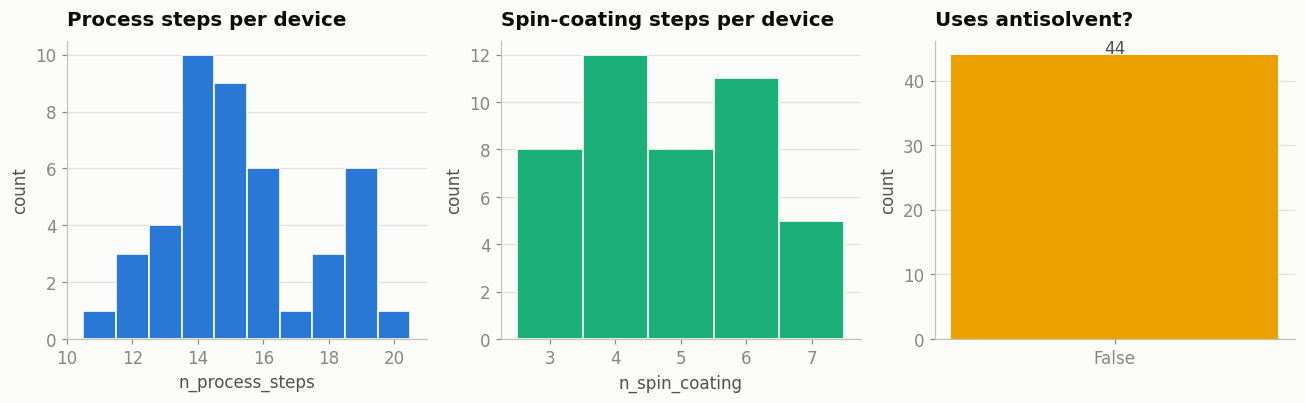

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
d = ml["n_process_steps"]
axes[0].hist(d, bins=range(int(d.min()), int(d.max()) + 2), color=CAT[0], align="left",
             edgecolor="#fcfcfb", linewidth=1.1, zorder=3)
style(axes[0], "Process steps per device", "n_process_steps", "count")
axes[0].grid(axis="x", visible=False)
d2 = ml["n_spin_coating"]
axes[1].hist(d2, bins=range(int(d2.min()), int(d2.max()) + 2), color=CAT[1], align="left",
             edgecolor="#fcfcfb", linewidth=1.1, zorder=3)
style(axes[1], "Spin-coating steps per device", "n_spin_coating", "count")
axes[1].grid(axis="x", visible=False)
av = ml["has_antisolvent"].value_counts()
axes[2].bar([str(i) for i in av.index], av.values, color=[CAT[2], MUTED][:len(av)],
            width=0.5, zorder=3)
for i, v in enumerate(av.values):
    axes[2].text(i, v + 0.3, str(v), ha="center", color=INK2)
style(axes[2], "Uses antisolvent?", None, "count")
axes[2].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

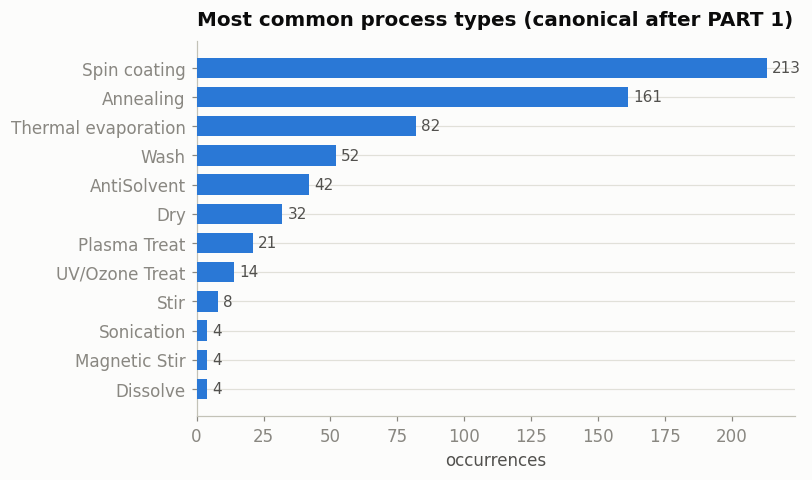

In [11]:
pt = tp["process"]["process_type"].dropna().value_counts().head(12)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(pt.index[::-1], pt.values[::-1], color=BLUE, height=0.7, zorder=3)
for y, v in enumerate(pt.values[::-1]):
    ax.text(v + 2, y, str(v), va="center", color=INK2, fontsize=10)
style(ax, "Most common process types (canonical after PART 1)", "occurrences", None)
plt.tight_layout(); plt.show()

## 4.6) Correlation ระหว่าง numeric features

หา multicollinearity และตัวแปรที่สัมพันธ์กับ PCE (diverging colormap: น้ำเงิน = +, แดง = −)
— ตอนนี้ `ff_max` correlate ได้อย่างมีความหมายแล้ว เพราะสเกลเดียวกันทั้งชุด


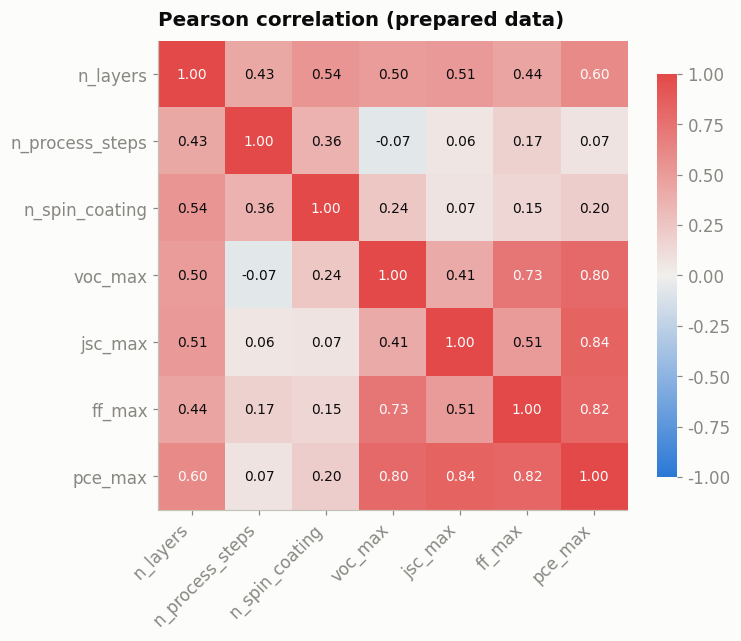

In [12]:
num = ["n_layers", "n_process_steps", "n_spin_coating",
       "voc_max", "jsc_max", "ff_max", "pce_max"]
corr = ml[num].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=45, ha="right")
ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                color="#fcfcfb" if abs(v) > 0.55 else INK, fontsize=9)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.outline.set_visible(False)
ax.set_title("Pearson correlation (prepared data)", loc="left", pad=10)
plt.tight_layout(); plt.show()

## 4.7) ความสัมพันธ์: อะไรขับ PCE?

PCE = Voc × Jsc × FF / Pin — ดูว่าตัวไหนสัมพันธ์กับ PCE มากสุด และ process ส่งผลไหม


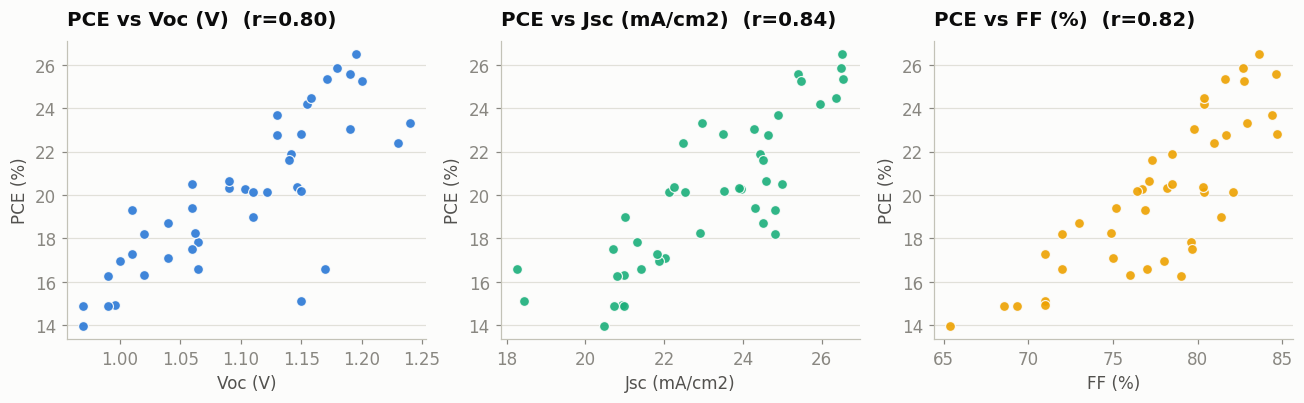

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (x, lab), c in zip(axes, [("voc_max", "Voc (V)"), ("jsc_max", "Jsc (mA/cm2)"),
                                  ("ff_max", "FF (%)")], CAT):
    sub = ml[[x, "pce_max"]].dropna()
    ax.scatter(sub[x], sub["pce_max"], s=42, color=c, edgecolor="#fcfcfb",
               linewidth=0.8, alpha=0.9, zorder=3)
    r = sub[x].corr(sub["pce_max"])
    style(ax, f"PCE vs {lab}  (r={r:.2f})", lab, "PCE (%)")
plt.tight_layout(); plt.show()

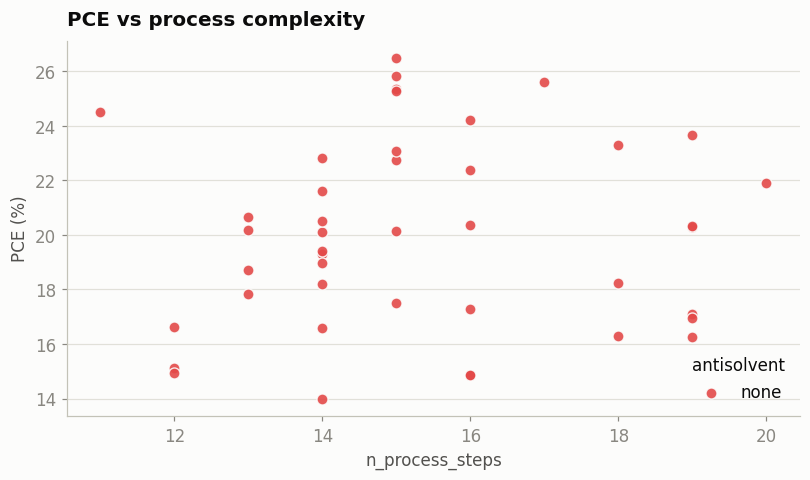

In [14]:
sub = ml[["n_process_steps", "pce_max", "has_antisolvent"]].dropna()
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for flag, c, lab in [(True, CAT[0], "antisolvent"), (False, CAT[5], "none")]:
    s = sub[sub["has_antisolvent"] == flag]
    if len(s):
        ax.scatter(s["n_process_steps"], s["pce_max"], s=52, color=c,
                   edgecolor="#fcfcfb", linewidth=0.9, alpha=0.9, zorder=3, label=lab)
ax.legend(frameon=False, loc="lower right", title="antisolvent")
style(ax, "PCE vs process complexity", "n_process_steps", "PCE (%)")
plt.tight_layout(); plt.show()

## 4.8) PCE ที่ดีที่สุดต่อ publication

HTL ในชุดข้อมูลนี้เกือบทั้งหมดเป็น **NiOx (~95%)** จึงเทียบ "ชนิด HTL" ไม่ได้ —
ตัวมันเองก็เป็น insight ว่า dataset ยังกระจุกตัว แทนที่ด้วยการดู best-PCE ราย paper
(แต่ละ paper = สูตร/กระบวนการหนึ่ง)


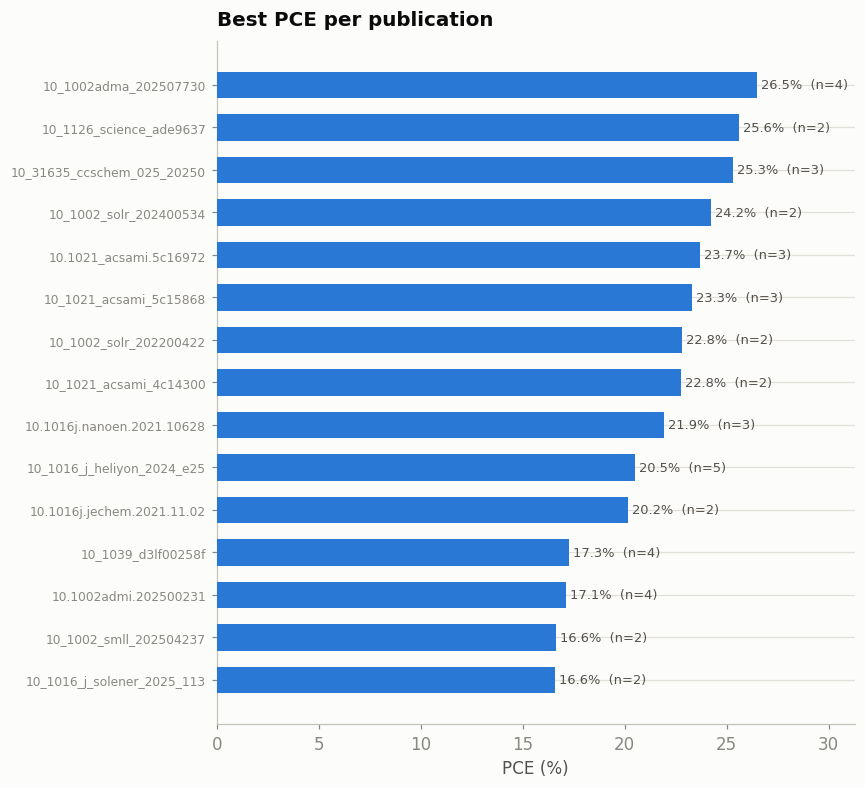

In [15]:
best = (ml.dropna(subset=["pce_max"])
          .groupby("doi_raw")
          .agg(best_pce=("pce_max", "max"), n=("device_id", "size"))
          .sort_values("best_pce"))
fig, ax = plt.subplots(figsize=(8, 0.42 * len(best) + 1))
ax.barh(range(len(best)), best["best_pce"], color=BLUE, height=0.62, zorder=3)
ax.set_yticks(range(len(best)))
ax.set_yticklabels([d[:26] for d in best.index], fontsize=8)
for y, (v, n) in enumerate(zip(best["best_pce"], best["n"])):
    ax.text(v + 0.2, y, f"{v:.1f}%  (n={n})", va="center", color=INK2, fontsize=8.5)
ax.set_xlim(0, best["best_pce"].max() * 1.18)
style(ax, "Best PCE per publication", "PCE (%)", None)
plt.tight_layout(); plt.show()

## 4.9) ความเสถียร (Stability)

ข้อมูล stability ยังบางมาก — ดูเท่าที่มี
โบนัสจาก PART 2: `temperature_c_parsed` / `humidity_pct_parsed` ใช้เป็นตัวเลขได้แล้ว
(จากเดิมที่เป็น `RT`, `50–60`, `60 ± 5` ซึ่ง parse ไม่ได้เลย)


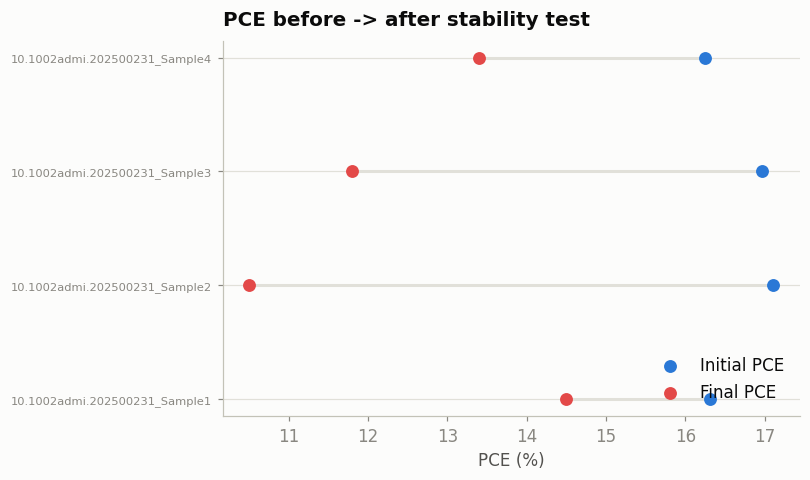

Mean PCE drop: 24.4%

Stability rows: 35 devices
เงื่อนไขทดสอบที่ใช้เป็นตัวเลขได้แล้ว (parsed ใน PART 2):
  temperature_c_parsed : 48 แถว
  humidity_pct_parsed  : 26 แถว


In [16]:
st = tp["stability"].copy()
have = st.dropna(subset=["initial_pce", "final_pce"])
if len(have):
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    y = np.arange(len(have))
    ax.hlines(y, have["final_pce"], have["initial_pce"], color=GRID, lw=2, zorder=2)
    ax.scatter(have["initial_pce"], y, s=55, color=CAT[0], zorder=3, label="Initial PCE")
    ax.scatter(have["final_pce"], y, s=55, color=CAT[5], zorder=3, label="Final PCE")
    ax.set_yticks(y); ax.set_yticklabels(have["device_id"], fontsize=7.5)
    ax.legend(frameon=False, loc="lower right")
    style(ax, "PCE before -> after stability test", "PCE (%)", None)
    plt.tight_layout(); plt.show()
    drop = (1 - have["final_pce"] / have["initial_pce"]).mul(100)
    print("Mean PCE drop: %.1f%%" % drop.mean())
else:
    print("No device has both initial_pce and final_pce yet")

print("\nStability rows:", st["device_id"].nunique(), "devices")
print("เงื่อนไขทดสอบที่ใช้เป็นตัวเลขได้แล้ว (parsed ใน PART 2):")
print("  temperature_c_parsed :", int(st["temperature_c_parsed"].notna().sum()), "แถว")
print("  humidity_pct_parsed  :", int(st["humidity_pct_parsed"].notna().sum()), "แถว")

## 4.10) สรุป (Key takeaways)

**ข้อมูล**
- 44 devices / 15 publications — Voc, Jsc, FF, PCE เก็บได้ค่อนข้างครบ; `bandgap_psk` มีน้อยแต่ความหมายถูกต้องแล้ว

**สิ่งที่สมุดนี้แก้ไปแล้ว (เทียบกับ flags ของ EDA เดิม)**
- ✅ FF สเกลเดียว (%) ทั้งชุด — correlate/เทรนได้จริง
- ✅ band gap แยกชั้น PSK ออกจาก HTL ด้วย `layer` column
- ✅ ชื่อ process/vendor/solvent เป็น canonical — นับความถี่ไม่แตกแท่ง
- ✅ thickness/humidity/temperature เป็นตัวเลข (`_parsed`)

**ยังค้าง (PART 5 + แผนงาน)**
- ⏳ material synonyms (`NiOx`/`NiOx NPs`/...) และคำพ้อง 10 กลุ่มใน properties
- ⏳ `process.parameter` ยังเป็นชุด string ปนหน่วย
- ⏳ regenerate `ml_dataset.csv` หลังปิดประเด็นข้างบน

**สัญญาณเชิงกระบวนการ** — ดูจากกราฟ §4.6–4.7: FF สัมพันธ์กับ PCE ชัดสุดในบรรดา JV components;
จำนวนขั้นตอนกระบวนการกระจาย ~11–20 ขั้น


---
# PART 5 · Explore ส่วนที่ *ยังไม่ apply* — รอยืนยันจากคนรู้โดเมน

สามประเด็นข้างล่างนี้เครื่องมือ text-clean ตัดสินเองไม่ได้ เพราะไม่ใช่เรื่อง "ตัวสะกด" แต่เป็นเรื่อง **ความหมาย**
— ต้องใช้ความรู้โดเมน/กติกาที่คนกำหนด โค้ดในส่วนนี้จึงทำหน้าที่ **รวบรวมหลักฐาน** จากข้อมูลจริงมาให้ตัดสินใจ
(ไม่มีการแก้ค่าใด ๆ ทั้งสิ้น)


## 5.1) คำพ้องเชิงความหมายใน `properties.property`

ทำไมยัง auto-merge ไม่ได้: key แบบตัด punctuation มองว่า `HI` กับ `Hysteresis Index` เป็นคนละคำโดยสิ้นเชิง
การจะบอกว่ามันคือตัวเดียวกันต้องรู้ฟิสิกส์ของมัน ไม่ใช่รู้ตัวสะกด

หลักฐานที่ใช้ตัดสิน: ถ้าเป็นตัวเดียวกันจริง **หน่วยควรตรงกัน + ช่วงค่าควรซ้อนทับกัน** ตารางข้างล่างรวมให้เทียบทีละกลุ่ม


In [17]:
SEMANTIC_CANDIDATES = {
    "1. Avg = Average?":       ["Average PCE", "Avg PCE", "Average Voc", "Avg Voc",
                                "Average Jsc", "Avg Jsc", "Average FF", "Avg FF"],
    "2. Hysteresis":           ["HI", "Hysteresis Index"],
    "3. Work function":        ["Work Function", "WF"],
    "4. Roughness":            ["Roughness RMS", "Roughness", "AFM RMS", "Rq",
                                "AFM rms (HTL)", "AFM rms (PVK)"],
    "5. Rrec":                 ["Rrec", "Rec", "EIS Rrec"],
    "6. Rs":                   ["Rs", "EIS Rs"],
    "7. Valence band":         ["VBM", "VB"],
    "8. Band gap":             ["PSK optical band gap", "HTL optical band gap",
                                "Bandgap", "Energy gap"],
    "9. Jsc จาก EQE":          ["Jsc EQE", "Integrated Jsc"],
    "10. Certified/Verified":  ["Certified PCE (RS)", "Certified PCE (FS)", "Verified PCE"],
}

p = tp["properties"]
rows = []
for group, names in SEMANTIC_CANDIDATES.items():
    for nm in names:
        sub = p[p["property"] == nm]
        if sub.empty:
            continue
        vals = pd.to_numeric(sub["value"], errors="coerce")
        rows.append({"group": group, "property": nm,
                     "n_rows": len(sub),
                     "n_devices": sub["device_id"].nunique(),
                     "units": ", ".join(sorted(sub["unit"].dropna().unique())) or "(ว่าง)",
                     "value_min": vals.min(), "value_max": vals.max(),
                     "example_remark": (sub["remarks"].dropna().iloc[0]
                                        if sub["remarks"].notna().any() else "")})

evidence = pd.DataFrame(rows)
evidence

,group,property,n_rows,n_devices,units,value_min,value_max,example_remark
0,1. Avg = Average?,Average PCE,14,14,%,12.940,2.448000e+01,"Average of 20 devices, Table S4"
1,1. Avg = Average?,Avg PCE,1,1,%,18.090,1.809000e+01,"Average of 20 devices, Table S4"
2,1. Avg = Average?,Average Voc,13,13,"%, V",0.970,1.240000e+00,"Average of 20 devices, Table S4"
3,1. Avg = Average?,Avg Voc,1,1,V,1.080,1.080000e+00,"Average of 20 devices, Table S4"
4,1. Avg = Average?,Average Jsc,13,13,"%, mA cm-2",20.460,2.516000e+01,"Average of 20 devices, Table S4"
5,1. Avg = Average?,Avg Jsc,1,1,mA cm-2,20.850,2.085000e+01,"Average of 20 devices, Table S4"
6,1. Avg = Average?,Average FF,13,13,%,0.690,8.160000e+01,"Average of 20 devices, Table S4"
7,1. Avg = Average?,Avg FF,1,1,%,80.030,8.003000e+01,"Average of 20 devices, Table S4"
8,2. Hysteresis,HI,11,11,%,0.750,1.090000e+01,Table 1
9,2. Hysteresis,Hysteresis Index,1,1,%,4.400,4.400000e+00,HI from J-V (Figure 3b inset)


## 5.2) อัตราส่วน solvent ที่เท่ากันเชิงคณิตศาสตร์

ทำไมยัง auto-merge ไม่ได้: `DMF/DMSO (8:2 V/V)` = `DMF/DMSO (4:1 v/v)` = `DMSO/DMF (1:4 v/v)`
ต้อง **คำนวณอัตราส่วน + สลับลำดับชื่อ solvent** ซึ่งเป็นการตีความสูตรเคมี ไม่ใช่ text cleaning
(และ `DMF/DMSO (800/200 µL)` เป็นปริมาตรสัมบูรณ์ที่บังเอิญอัตราส่วนเท่ากัน — ควร merge ไหมยิ่งต้องให้คนตัดสิน)

โค้ดนี้ parse คู่ solvent + อัตราส่วน แล้วเรียงชื่อให้คงที่ เพื่อหากลุ่มที่ค่าเท่ากันแต่เขียนต่างกัน


In [18]:
pat = re.compile(r"^(?P<a>[A-Za-z0-9]+)\s*[/:]\s*(?P<b>[A-Za-z0-9]+)\s*"
                 r"\((?P<x>\d+(?:\.\d+)?)\s*[:/]\s*(?P<y>\d+(?:\.\d+)?)\s*(?P<unit>[^)]*)\)$")

parsed = []
for val, n in sorted(Counter(tp["materials"]["solvent"].dropna()).items()):
    m = pat.match(val)
    if not m:
        continue
    a, b, x, y = m["a"], m["b"], float(m["x"]), float(m["y"])
    if a.lower() > b.lower():                 # เรียงชื่อ solvent ให้คงที่ + กลับอัตราส่วนตาม
        a, b, x, y = b, a, y, x
    parsed.append({"solvent_raw": val, "n_rows": n, "pair": f"{a}/{b}",
                   "ratio": round(x / y, 4), "unit_text": m["unit"].strip() or "(ไม่ระบุ)"})

par = pd.DataFrame(parsed)
dup = (par[par.duplicated(["pair", "ratio"], keep=False)]
         .sort_values(["pair", "ratio", "solvent_raw"])
         .reset_index(drop=True))
print(f"parse ได้ {len(par)} รูปแบบ, กลุ่มที่อัตราส่วนเท่ากันแต่เขียนต่างกัน: "
      f"{dup.groupby(['pair', 'ratio']).ngroups} กลุ่ม")
dup

parse ได้ 9 รูปแบบ, กลุ่มที่อัตราส่วนเท่ากันแต่เขียนต่างกัน: 1 กลุ่ม


,solvent_raw,n_rows,pair,ratio,unit_text
0,DMF/DMSO (4:1 v/v),114,DMF/DMSO,4.0,v/v
1,DMF/DMSO (4:1),18,DMF/DMSO,4.0,(ไม่ระบุ)
2,DMF/DMSO (800/200 µL),10,DMF/DMSO,4.0,µL
3,DMF/DMSO (8:2 V/V),10,DMF/DMSO,4.0,V/V
4,DMSO/DMF (1:4 v/v),25,DMF/DMSO,4.0,v/v


## 5.3) FF ปนสเกล: สัดส่วน 0–1 กับเปอร์เซ็นต์

> ✅ **อัปเดต:** กติกาถูกเคาะและ**ทำแล้วใน PART 3** (`value_parsed` = ×100 ให้ฝั่ง fraction)
> เซลล์นี้คงไว้เป็น**หลักฐานของสภาพข้อมูลดิบ** — โค้ดอ่านจากคอลัมน์ `value` (raw) จึงยังเห็นสองสเกลตามต้นฉบับ

ทำไมยัง auto-fix ไม่ได้: ค่า `0.76` กับ `76` คือค่าเดียวกันคนละสเกล การแปลง (×100) เป็นการ **แก้ตัวเลข**
ไม่ใช่แก้ข้อความ — ต้องกำหนดกติกา, บันทึกว่าแก้แถวไหน และตัดสินเคสก้ำกึ่งด้วยตาคน
ประเด็นนี้เป็นต้นเหตุที่ `ff_max` ใน `ml_dataset.csv` ใช้เทรนตรง ๆ ไม่ได้

โค้ดนี้แยกแถว FF ตามสเกล + ระบุว่ามาจาก DOI ไหน


In [19]:
ffp = p[p["property"].str.contains(r"\bFF\b")].copy()
ffp["val"] = pd.to_numeric(ffp["value"], errors="coerce")
ffp["scale"] = ffp["val"].le(1).map({True: "fraction (0-1)", False: "percent"})

summary = (ffp.groupby("scale")
              .agg(n_rows=("val", "size"),
                   n_devices=("device_id", "nunique"),
                   val_min=("val", "min"), val_max=("val", "max"),
                   units=("unit", lambda s: ", ".join(sorted(set(s.dropna()))) or "(ว่าง)")))
display(summary)

frac_doi = sorted(set(ffp.loc[ffp["scale"] == "fraction (0-1)", "device_id"]
                         .str.replace(r"_Sample\d+$", "", regex=True)))
print("DOI ที่รายงาน FF เป็นสัดส่วน 0-1:")
for d in frac_doi:
    print("  -", d)

,n_rows,n_devices,val_min,val_max,units
scale,,,,,
fraction (0-1),8,6,0.69,0.79,(ว่าง)
percent,59,37,65.39,84.68,%


DOI ที่รายงาน FF เป็นสัดส่วน 0-1:
  - 10.1002admi.202500231
  - 10_1016_j_solener_2025_113286


## 5.4) สรุปการตัดสินใจที่ค้างทั้งหมด + แผนไปต่อ

### (ก) assumption ที่ฝังใน PART 2–3 — ใช้งานได้แล้วแต่ควรยืนยัน

| ประเด็น | ค่าที่ใช้ตอนนี้ | ทางเลือกอื่น | แก้ที่ไหน |
|---|---|---|---|
| `RT` = กี่องศา | 25.0 °C | 20–22 °C ก็พบในบาง paper | `CONFIG["RT_CELSIUS"]` (PART 2) |
| ตัวแทนช่วง `a-b` | ค่ากลาง `(a+b)/2` | min (conservative) หรือเก็บ 2 features | PART 2 §2.2–2.3 |
| `Cr + Au` = `4, 100` | ผลรวม 104 nm | ใช้เฉพาะชั้นนำไฟฟ้าหลัก (Au 100) | PART 2 §2.2 |
| retention `< 55` | parsed=55 + ธง `<` | ตัดทิ้ง / treat เป็น censored | ธง `retention_pct_censor` |
| sheet resistance ใน purity | ติดธง `sheet_resistance_misfiled` | ย้ายเป็น property ของ substrate | รอออกแบบ schema |
| stat `avg` / `verified` | เก็บแยกตามที่เขียน | รวมเป็น `average` / `certified` | `STAT_MERGE_PENDING` (PART 3 §3.1) |

### (ข) รอคำตอบโดเมนโดยตรง (หลักฐานอยู่ใน §5.1–5.2 ข้างบน)

1. คำพ้อง 10 กลุ่มใน `properties` — ตาราง §5.1 มีหน่วย+ช่วงค่า+remark ช่วยตัดสินครบ
2. solvent ratio: 5 รูปแบบเขียน = DMF:DMSO 4:1 (177 แถว) จะ normalize เป็นรูปเดียวไหม
   และ `800/200 µL` (ปริมาตรสัมบูรณ์) นับเป็นอัตราส่วนเดียวกันไหม
3. material synonyms เช่น `NiOx` / `NiOx NPs` / `NiOx Nanoparticles` (ดูกราฟ §4.4)

### (ค) หลังยืนยันแล้ว ลำดับงานคือ

```
ยืนยัน (ข)  →  apply semantic merge ที่ base_property / material / solvent
            →  regenerate ml_dataset.csv จาก prepared (แทน build_ml_table เดิม)
            →  feature engineering + โมเดลทำนาย PCE / stability จาก process
               (group-CV ตาม DOI, โมเดลตีความได้ — ตามข้อจำกัด N=44)
```
